In [1]:
try:
    import google.colab
    %pip install -q ugropy
except ImportError:
    pass

## The Groups class

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ipqa-research/ugropy/blob/main/docs/source/tutorial/easy_way.ipynb)


`ugropy` is relatively straightforward to use, but let's explore what it has to 
offer. Now, let's start with the easy methods...

We'll utilize the Groups class to retrieve the subgroups of all the models 
supported by `ugropy`.

### Basic usage: getting subgroups

In [2]:
from ugropy import Groups

carvone = Groups("carvone")

carvone.unifac.subgroups

{'CH3': 2, 'CH2': 1, 'CH': 1, 'CH2=C': 1, 'CH=C': 1, 'CH2CO': 1}

`ugropy` utilizes `PubChemPy` ([link](https://github.com/mcs07/PubChemPy)) to
access `PubChem` and retrieve the SMILES representation of the molecule.
`ugropy` employs the SMILES representation along with the `rdkit`
([link](https://github.com/rdkit/rdkit)) and `Pulp` ([link](https://github.com/coin-or/pulp))
libraries to identify the functional groups of the molecules.

The complete signature of the Groups class is as follows:

In [3]:
from ugropy import DefaultSolver

carvone = Groups(
    identifier="carvone",
    identifier_type="name",
    solver=DefaultSolver,
    search_multiple_solutions=False,
    normal_boiling_temperature=None
)

The `identifier_type` argument (default: "name") can be set to "name", "smiles"
or "mol".

When "name" is set, `ugropy` will use the identifier argument to search in
Pubchem for the canonical SMILES of the molecule.

When "smiles" is set, `ugropy` uses it directly, this also means that the 
library will not suffer the overhead of searching on Pubchem. Try it yourself:

In [4]:
carvone = Groups(
    identifier="CC1=CCC(CC1=O)C(=C)C",
    identifier_type="smiles",
)

carvone.unifac.subgroups

{'CH3': 2, 'CH2': 1, 'CH': 1, 'CH2=C': 1, 'CH=C': 1, 'CH2CO': 1}

If you are familiar with the `rdkit` library, you'll know that there are
numerous ways to define a molecule (e.g., SMILES, SMARTS, PDB file, InChIKey,
etc.). `ugropy` supports the provision of a Mol object from the `rdkit`
library.

In [5]:
from rdkit import Chem

mol_obj = Chem.MolFromInchi("InChI=1S/C10H14O/c1-7(2)9-5-4-8(3)10(11)6-9/h4,9H,1,5-6H2,2-3H3")

carvone = Groups(
    identifier=mol_obj,
    identifier_type="mol",
    normal_boiling_temperature=None
)

carvone.unifac.subgroups

{'CH3': 2, 'CH2': 1, 'CH': 1, 'CH2=C': 1, 'CH=C': 1, 'CH2CO': 1}

The current supported models are the classic liquid-vapor UNIFAC, Predictive
Soave-Redlich-Kwong (PSRK), Joback, Dortmund and Abdulelah-Gani. You can access the 
functional groups this way:

In [6]:
carvone = Groups("carvone")

print(carvone.unifac.subgroups)

print(carvone.psrk.subgroups)

print(carvone.joback.subgroups)

print(carvone.dortmund.subgroups)

print(carvone.agani.primary.subgroups)

{'CH3': 2, 'CH2': 1, 'CH': 1, 'CH2=C': 1, 'CH=C': 1, 'CH2CO': 1}
{'CH3': 2, 'CH2': 1, 'CH': 1, 'CH2=C': 1, 'CH=C': 1, 'CH2CO': 1}
{'-CH3': 2, '=CH2': 1, '=C<': 1, 'ring-CH2-': 2, 'ring>CH-': 1, 'ring=CH-': 1, 'ring=C<': 1, '>C=O (ring)': 1}
{'CH3': 2, 'CH2=C': 1, 'CH=C': 1, 'CH2CO': 1, 'CY-CH2': 1, 'CY-CH': 1}
{'CH3': 2, 'CH2=C': 1, 'CH2 (cyclic)': 2, 'CH (cyclic)': 1, 'CH=C (cyclic)': 1, 'CO (cyclic)': 1}


### Estimating thermophysical properties

You can obtain more information about the molecule from each model. For
example, UNIFAC and PSRK are Excess Gibbs Models, so you can obtain the
estimation of the $R$ and $Q$ values of the molecule (molecule's reduced Van
der Wals volume and area)

In [7]:
print("UNIFAC R: ", carvone.unifac.r)
print("UNIFAC Q: ", carvone.unifac.q)

print("PSRK R: ", carvone.psrk.r)
print("PSRK Q: ", carvone.psrk.q)

UNIFAC R:  6.3751
UNIFAC Q:  5.308
PSRK R:  6.3751
PSRK Q:  5.308


On the Joback model, you can obtain the estimation of different properties.
We will discuss the properties estimators later.

In [8]:
print(carvone.joback.acentric_factor)
print(carvone.joback.normal_boiling_point)
print(carvone.joback.critical_temperature)
print(carvone.joback.critical_pressure)
print(carvone.joback.critical_volume)
print(carvone.joback.vapor_pressure(430))

0.4189559236029428 dimensionless
516.47 kelvin
742.5207962108279 kelvin
28.596757127741714 bar
503.5 centimeter ** 3 / mole
0.09232883692318564 bar


If the `normal_boiling_temperature` parameter is provided, it is used in
the Joback properties calculations instead of the Joback-estimated normal
boiling temperature (refer to the Joback tutorial).

Finally the `search_multiple_solutions` parameter is used to determine if the 
solver should return multiple solutions or not. If set to True, the solver will
return multiple solutions if they exist. If set to False, the solver will 
return only one solution. The default value is False. In next sections we will
explore in more detail how to obtain more solutions from the solver.

### Obtaining multiple solutions

In [9]:
# Example of multiple solutions
molecule = Groups("CCCC1=CC=C(CC(=O)OC)C=C1", "smiles", search_multiple_solutions=True)

molecule.unifac

As you can see we obtained a list of `GibbsFragmentationResult` objects. When
`search_multiple_solutions` is set to True, the result will always be a list,
regardless of the number of solutions found.

We can check both solutions:

In [10]:
print(molecule.unifac[0].subgroups)
print(molecule.unifac[1].subgroups)

{'CH3': 2, 'CH2': 1, 'ACH': 4, 'ACCH2': 2, 'COO': 1}
{'CH3': 2, 'CH2': 1, 'ACH': 4, 'AC': 1, 'ACCH2': 1, 'CH2COO': 1}


Multiple solution searching is intended to get all the solutions for a given
model and try different representations of the molecule to obtain properties.
For example, different UNIFAC representations could lead to different
liquid-liquid or liquid-vapor equilibrium predictions.


The full documentation of the `Groups` class may be accessed in the API
documentation. You can inspect the full API details using Python's built-in
help(Groups), Groups?, or by visiting the official API documentation.

### Visualizing your results

Also, you can visualize your fragmentations results. Let's see the multiple
solutions obtained before:

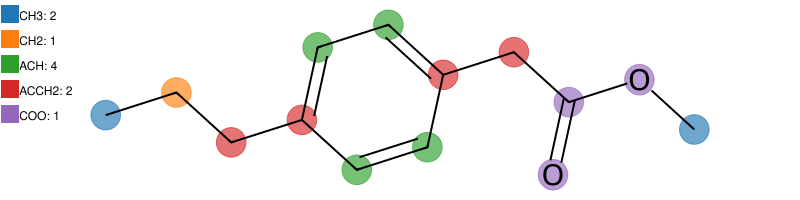

In [11]:
molecule.unifac[0].draw(width=800)

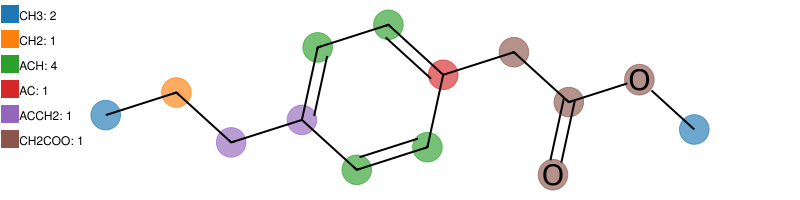

In [12]:
molecule.unifac[1].draw(width=800)

Let's also draw the carvone solutions obtained before:

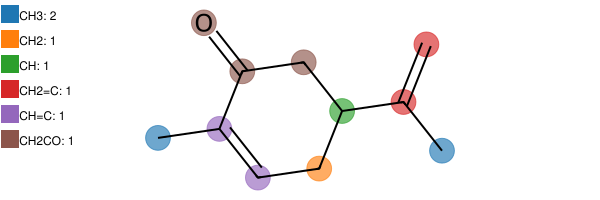

In [13]:
carvone.unifac.draw(width=600)

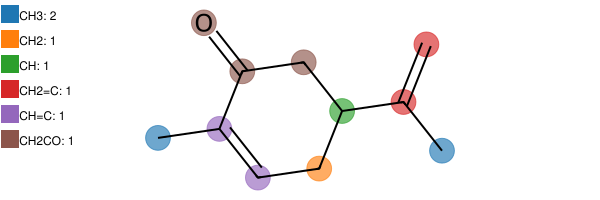

In [14]:
carvone.psrk.draw(width=600)

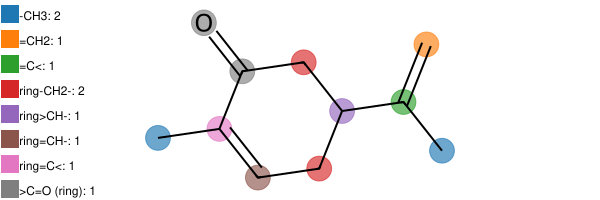

In [15]:
carvone.joback.draw(width=600)

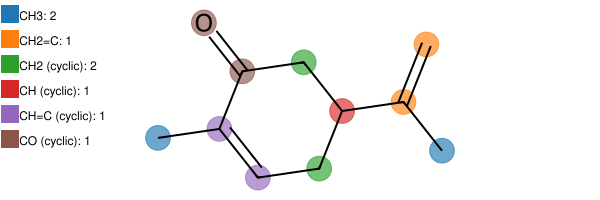

In [16]:
carvone.agani.primary.draw(width=600)

You can save the figure by doing:

In [17]:
with open("figure.svg", "w") as f:
    f.write(carvone.unifac.get_solution_svg(width=600))

Please, check the API documentation of the draw function to learn all their
parameters:

```
carvone.unifac.draw?
```

Finally, lets draw the `ugropy` logo:

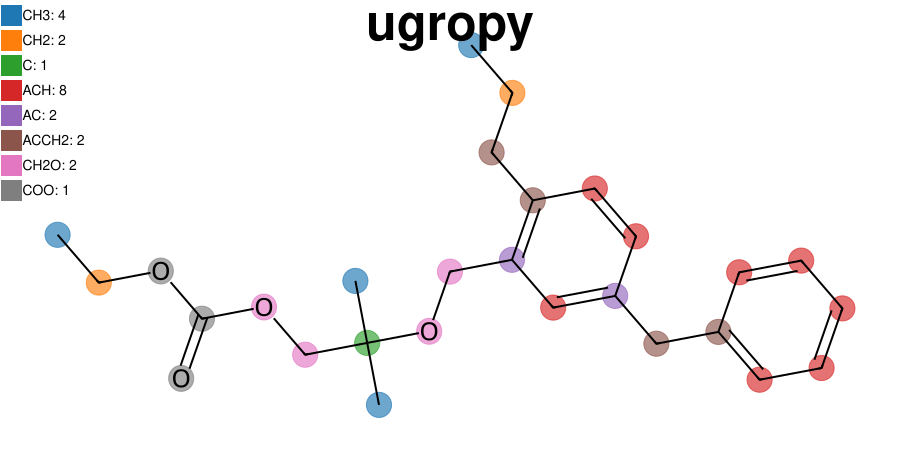

In [18]:
mol = Groups("CCCC1=C(COC(C)(C)COC(=O)OCC)C=C(CC2=CC=CC=C2)C=C1", "smiles")

mol.unifac.draw(
    title="ugropy",
    width=900,
    height=450,
    title_font_size=50,
    legend_font_size=14
)
